# Solution: Mission 02 — Multi-Source Data Integration Hub

This notebook is one possible solution. Try the mission yourself before you read it.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets

COLS = ["tpep_pickup_datetime", "PULocationID", "DOLocationID", "trip_distance", "fare_amount", "total_amount"]
jan = pd.read_parquet(datasets.taxi("2024-01"), columns=COLS)          # source 1: Parquet files from the trip system
feb = pd.read_parquet(datasets.taxi("2024-02"), columns=COLS)
zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))            # source 2: CSV reference table
borough_info = pd.read_json(pd.io.common.StringIO("""[
  {"borough": "Manhattan", "population_2020": 1694251},
  {"borough": "Brooklyn", "population_2020": 2736074},
  {"borough": "Queens", "population_2020": 2405464},
  {"borough": "Bronx", "population_2020": 1472654},
  {"borough": "Staten Island", "population_2020": 495747}
]"""))                                                                  # source 3: JSON from a planning system (US Census 2020)
print(len(jan), len(feb), zones.shape, borough_info.shape)

2964624 3007526 (265, 4) (5, 2)


## Task 1: Combine Months

In [2]:
trips = pd.concat([jan.assign(month="2024-01"), feb.assign(month="2024-02")], ignore_index=True)
in_month = trips["tpep_pickup_datetime"].dt.strftime("%Y-%m") == trips["month"]
trips = trips[in_month & trips["fare_amount"].between(3, 500)].reset_index(drop=True)
days = {"2024-01": 31, "2024-02": 29}
print(trips.groupby("month").size().to_dict())

{'2024-01': 2924610, '2024-02': 2962465}


## Task 2: Add Zones with Validation

In [3]:
z = zones.rename(columns={"LocationID": "zone_id"})[["zone_id", "Borough", "Zone"]]
n0 = len(trips)
trips = (trips.merge(z.add_prefix("pu_"), left_on="PULocationID", right_on="pu_zone_id", how="left", validate="m:1", indicator="pu_match")
              .merge(z.add_prefix("do_"), left_on="DOLocationID", right_on="do_zone_id", how="left", validate="m:1", indicator="do_match"))
assert len(trips) == n0, "a merge changed the number of rows"
print("pickup ids without a zone row:", (trips["pu_match"] == "left_only").sum(),
      "| drop-off ids without a zone row:", (trips["do_match"] == "left_only").sum())
unknown = trips["pu_Borough"].isin(["Unknown", "N/A"]) | trips["pu_Borough"].isna() | \
          trips["do_Borough"].isin(["Unknown", "N/A"]) | trips["do_Borough"].isna()
print(f"trips with an unknown borough (zones 264/265 or missing): {unknown.sum():,} ({unknown.mean():.2%}) -> excluded from borough analysis")
known = trips[~unknown & trips["pu_Borough"].isin(borough_info["borough"]) & trips["do_Borough"].isin(borough_info["borough"])]
print(f"trips within the five boroughs: {len(known):,}")

pickup ids without a zone row: 0 | drop-off ids without a zone row: 0
trips with an unknown borough (zones 264/265 or missing): 59,123 (1.00%) -> excluded from borough analysis


trips within the five boroughs: 5,813,969


Trips to or from Newark Airport (`EWR`, in New Jersey) are outside the five boroughs, so the borough analysis excludes them together with the unknown zones.

## Task 3: Trips per 1,000 Residents

In [4]:
per_borough = (known.groupby(["pu_Borough", "month"]).size().rename("trips").reset_index()
               .merge(borough_info, left_on="pu_Borough", right_on="borough", how="left", validate="m:1"))
per_borough["trips_per_day"] = per_borough["trips"] / per_borough["month"].map(days)
per_borough["daily_trips_per_1000"] = 1000 * per_borough["trips_per_day"] / per_borough["population_2020"]
table = per_borough.pivot(index="borough", columns="month", values="daily_trips_per_1000").round(2)
table.sort_values("2024-01", ascending=False)

month,2024-01,2024-02
borough,,
Manhattan,49.46,54.07
Queens,3.46,3.39
Brooklyn,0.29,0.34
Bronx,0.15,0.16
Staten Island,0.00,0.00


## Task 4: Flow Matrix

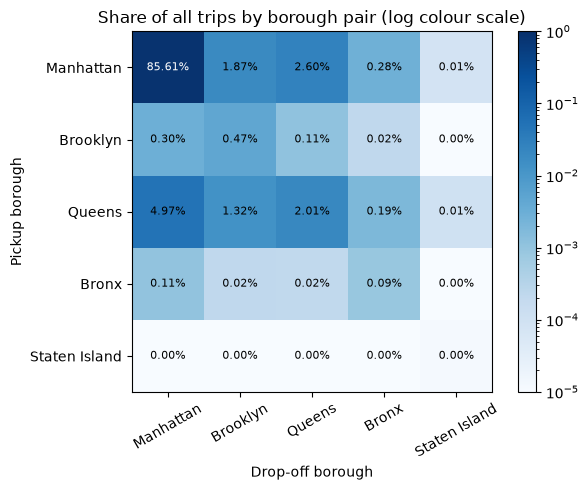

In [5]:
order = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"]
flows = pd.crosstab(known["pu_Borough"], known["do_Borough"], normalize="all").reindex(index=order, columns=order).fillna(0)
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(flows, cmap="Blues", norm=plt.matplotlib.colors.LogNorm(vmin=1e-5, vmax=1))
ax.set(xticks=range(5), yticks=range(5), xticklabels=order, yticklabels=order, xlabel="Drop-off borough",
       ylabel="Pickup borough", title="Share of all trips by borough pair (log colour scale)")
ax.tick_params(axis="x", rotation=30)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{100 * flows.iloc[i, j]:.2f}%", ha="center", va="center", fontsize=8,
                color="white" if flows.iloc[i, j] > 0.05 else "black")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## Task 5: Cross-Borough Trips

In [6]:
known = known.assign(cross=known["pu_Borough"] != known["do_Borough"])
print(f"share of trips that cross a borough boundary: {known['cross'].mean():.1%}")
known.groupby("pu_Borough")["cross"].agg(["mean", "size"]).rename(columns={"mean": "cross_share", "size": "trips"}) \
     .sort_values("trips", ascending=False).round(3)

share of trips that cross a borough boundary: 11.8%


,cross_share,trips
pu_Borough,,
Manhattan,0.053,5254146
Queens,0.763,494141
Brooklyn,0.479,51957
Bronx,0.633,13616
Staten Island,0.385,109


## Task 6: Change from January to February (per Day)

In [7]:
pairs = known.groupby(["pu_Borough", "do_Borough", "month"]).size().unstack("month").fillna(0)
pairs = pairs.div(pd.Series(days), axis=1)                     # trips per day
pairs["change_per_day"] = pairs["2024-02"] - pairs["2024-01"]
pairs["change_%"] = 100 * pairs["change_per_day"] / pairs["2024-01"]
big = pairs[pairs["2024-01"] >= 50]                             # ignore tiny pairs
print(big.sort_values("change_per_day").round(1).iloc[[0, 1, -2, -1]])

month                  2024-01  2024-02  change_per_day  change_%
pu_Borough do_Borough                                            
Queens     Queens       2004.1   1897.0          -107.1      -5.3
           Brooklyn     1300.3   1250.4           -49.9      -3.8
Manhattan  Brooklyn     1666.1   1961.1           294.9      17.7
           Manhattan   79420.3  86739.4          7319.1       9.2


## Task 7: Findings

In [8]:
mh = known["pu_Borough"].eq("Manhattan").mean()
within_mh = ((known["pu_Borough"] == "Manhattan") & (known["do_Borough"] == "Manhattan")).mean()
top_rate = table["2024-01"].idxmax()
print(f"1. Yellow taxis are a Manhattan service: {mh:.0%} of trips start there and {within_mh:.0%} stay inside Manhattan.")
print(f"2. Per resident, {top_rate} generates by far the most trips "
      f"({table.loc[top_rate, '2024-01']:.1f} per 1,000 residents per day in January); the outer boroughs generate far fewer.")
q = known[known["pu_Borough"] == "Queens"]["cross"].mean()
print(f"3. Trips from Queens are mostly cross-borough ({q:.0%}), driven by the two airports; "
      f"the largest day-to-day changes between months are listed in Task 6.")

1. Yellow taxis are a Manhattan service: 90% of trips start there and 86% stay inside Manhattan.
2. Per resident, Manhattan generates by far the most trips (49.5 per 1,000 residents per day in January); the outer boroughs generate far fewer.


3. Trips from Queens are mostly cross-borough (76%), driven by the two airports; the largest day-to-day changes between months are listed in Task 6.
